<a href="https://colab.research.google.com/github/venkat-prasath/uk-retail-sales-customer-analytics/blob/main/notebooks/retail_sales_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
import pandas as pd
import requests
import zipfile
import io

# Download the dataset ZIP file
url = "https://archive.ics.uci.edu/static/public/352/online+retail.zip"

response = requests.get(url)
response.raise_for_status()

# Open the ZIP file in memory
with zipfile.ZipFile(io.BytesIO(response.content)) as z:
    print("Files found:", z.namelist())

    # Find the Excel file inside the ZIP
    excel_file = next(
        name for name in z.namelist()
        if name.lower().endswith((".xlsx", ".xls"))
    )

    # Read the Excel file
    with z.open(excel_file) as f:
        df = pd.read_excel(f)

# Display the results
print("Dataset shape:", df.shape)
display(df.head())

Files found: ['Online Retail.xlsx']
Dataset shape: (541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [3]:
# 1. Inspect the dataset
print("Original rows:", len(df))
print("Original columns:", df.shape[1])

print("\nColumn names:")
print(df.columns.tolist())

# 2. Check missing values
print("\nMissing values:")
print(df.isnull().sum())

# 3. Check duplicate records
print("\nDuplicate rows:", df.duplicated().sum())

# 4. Check invalid quantities and prices
print("\nNon-positive quantities:", (df["Quantity"] <= 0).sum())
print("Non-positive prices:", (df["UnitPrice"] <= 0).sum())

# 5. Check invoice dates
print("\nDate range:")
print(df["InvoiceDate"].min(), "to", df["InvoiceDate"].max())

Original rows: 541909
Original columns: 8

Column names:
['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']

Missing values:
InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

Duplicate rows: 5268

Non-positive quantities: 10624
Non-positive prices: 2517

Date range:
2010-12-01 08:26:00 to 2011-12-09 12:50:00


In [4]:
# Make a working copy of the original dataset
retail = df.copy()

# Convert invoice dates to datetime
retail["InvoiceDate"] = pd.to_datetime(
    retail["InvoiceDate"], errors="coerce"
)

# Remove duplicate records and rows missing essential fields
retail = retail.drop_duplicates()

retail = retail.dropna(
    subset=["InvoiceNo", "StockCode", "Quantity",
            "UnitPrice", "InvoiceDate"]
)

# Remove invalid quantities and prices
retail = retail[
    (retail["Quantity"] > 0) &
    (retail["UnitPrice"] > 0)
].copy()

# Exclude cancelled invoices (invoice numbers beginning with C)
retail = retail[
    ~retail["InvoiceNo"].astype(str).str.startswith("C")
].copy()

# Calculate transaction-line revenue
retail["Revenue"] = retail["Quantity"] * retail["UnitPrice"]

print("Original rows:", len(df))
print("Cleaned rows:", len(retail))
print("Rows removed:", len(df) - len(retail))

display(retail.head())

Original rows: 541909
Cleaned rows: 524878
Rows removed: 17031


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Revenue
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34


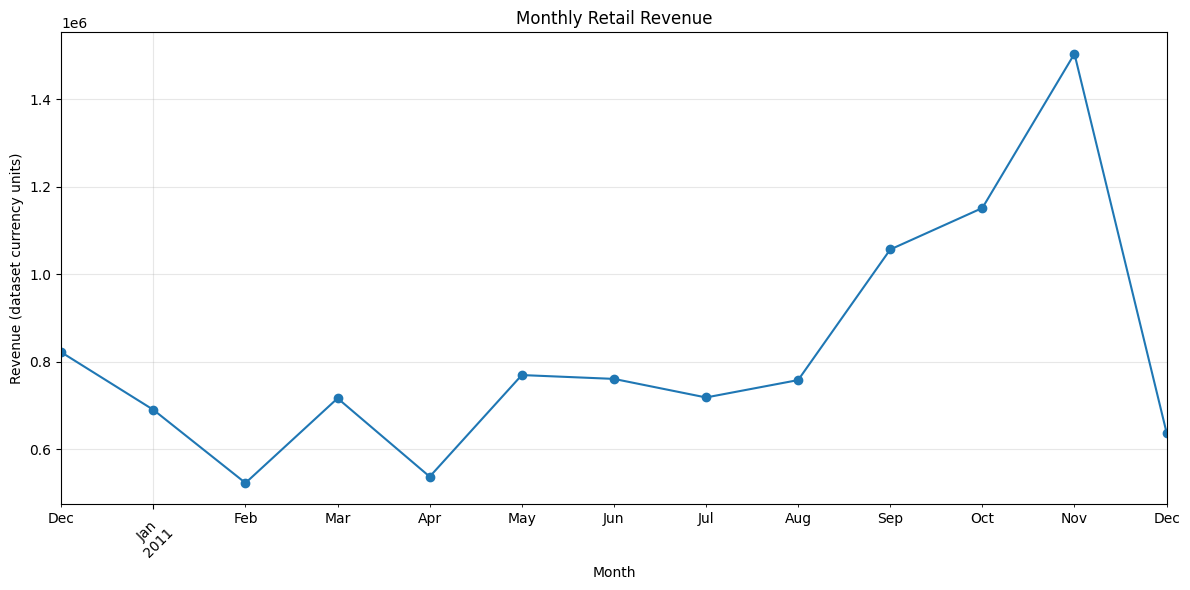

In [5]:
import matplotlib.pyplot as plt

# Summarise revenue by month
monthly_revenue = (
    retail.groupby(retail["InvoiceDate"].dt.to_period("M"))["Revenue"]
    .sum()
)

# Plot monthly revenue
plt.figure(figsize=(12, 6))
monthly_revenue.plot(kind="line", marker="o")

plt.title("Monthly Retail Revenue")
plt.xlabel("Month")
plt.ylabel("Revenue (dataset currency units)")
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

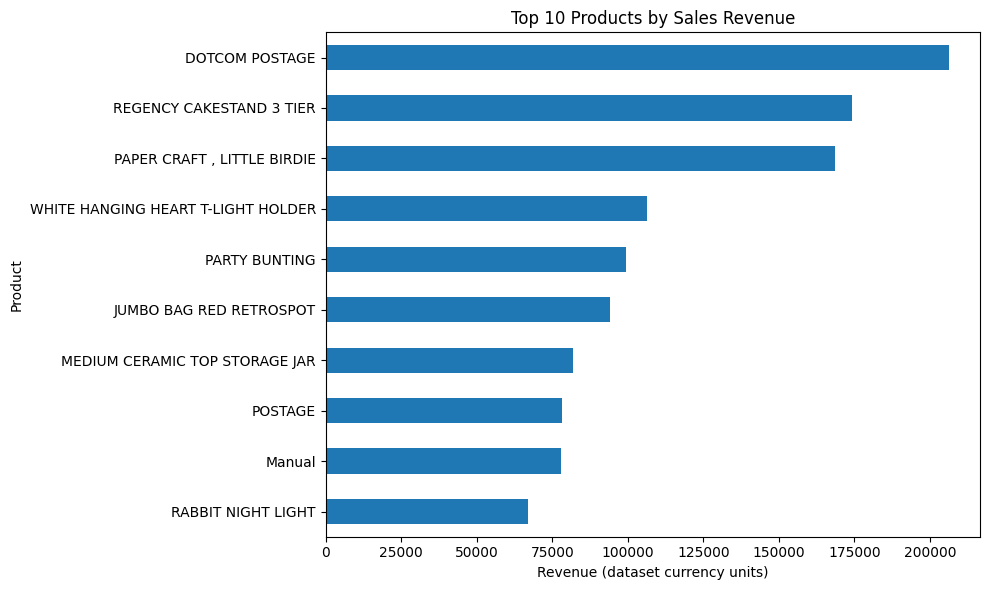

In [6]:
top_products = (
    retail.groupby("Description")["Revenue"]
    .sum()
    .nlargest(10)
    .sort_values()
)

plt.figure(figsize=(10, 6))
top_products.plot(kind="barh")

plt.title("Top 10 Products by Sales Revenue")
plt.xlabel("Revenue (dataset currency units)")
plt.ylabel("Product")
plt.tight_layout()
plt.show()

,Country,Revenue
0,United Kingdom,9001744.094
1,Netherlands,285446.340
2,EIRE,283140.520
3,Germany,228678.400
4,France,209625.370
5,Australia,138453.810
6,Spain,61558.560
7,Switzerland,57067.600
8,Belgium,41196.340
9,Sweden,38367.830


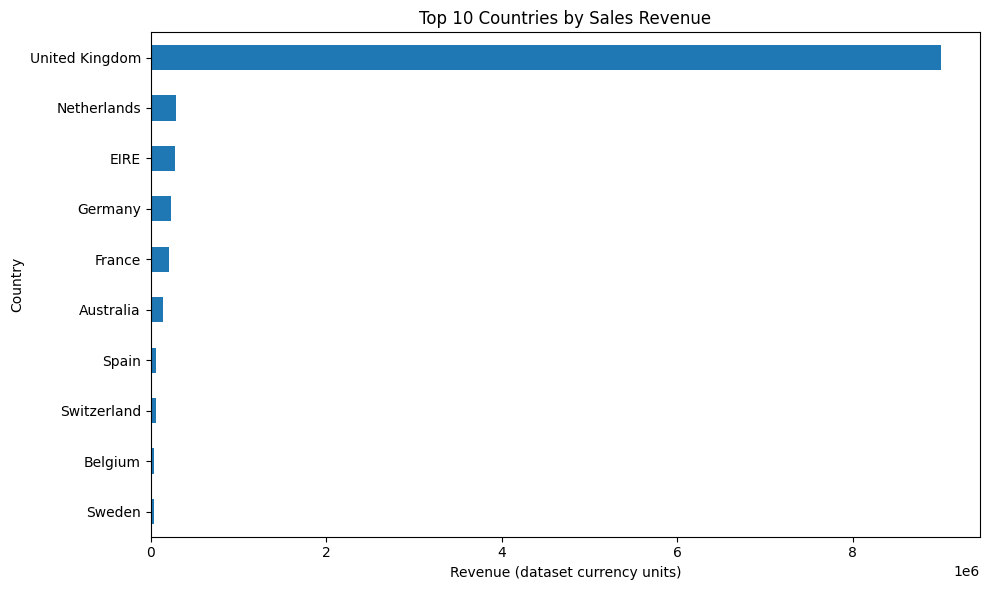

In [7]:
# Top 10 countries by recorded sales revenue
country_sales = (
    retail.groupby("Country")["Revenue"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

display(country_sales.reset_index())

country_sales.sort_values().plot(
    kind="barh",
    figsize=(10, 6),
    title="Top 10 Countries by Sales Revenue"
)

plt.xlabel("Revenue (dataset currency units)")
plt.ylabel("Country")
plt.tight_layout()
plt.show()

In [8]:
# Keep transactions with known customer IDs
customer_data = retail.dropna(subset=["CustomerID"]).copy()

# Calculate customer-level metrics
customer_summary = (
    customer_data.groupby("CustomerID")
    .agg(
        TotalRevenue=("Revenue", "sum"),
        NumberOfInvoices=("InvoiceNo", "nunique"),
        TotalItems=("Quantity", "sum")
    )
    .sort_values("TotalRevenue", ascending=False)
)

print("Top 10 customers by recorded revenue:")
display(customer_summary.head(10))

print("\nNumber of identifiable customers:",
      customer_data["CustomerID"].nunique())

Top 10 customers by recorded revenue:


,TotalRevenue,NumberOfInvoices,TotalItems
CustomerID,,,
14646.0,280206.02,73,196915
18102.0,259657.30,60,64124
17450.0,194390.79,46,69973
16446.0,168472.50,2,80997
14911.0,143711.17,201,80240
12415.0,124914.53,21,77374
14156.0,117210.08,55,57768
17511.0,91062.38,31,64549
16029.0,80850.84,63,40108



Number of identifiable customers: 4338


In [10]:
import sqlite3
import pandas as pd

# Create the SQL database connection
conn = sqlite3.connect(":memory:")

# Load your cleaned retail data into SQL
retail.to_sql(
    "retail_sales",
    conn,
    if_exists="replace",
    index=False
)

print("Database created successfully!")

# Check the number of records
query = """
SELECT COUNT(*) AS total_records
FROM retail_sales;
"""

result = pd.read_sql_query(query, conn)
display(result)

Database created successfully!


,total_records
0,524878


In [11]:
query = """
SELECT
    ROUND(SUM(Revenue), 2) AS total_revenue,
    COUNT(*) AS total_transactions,
    COUNT(DISTINCT InvoiceNo) AS total_invoices,
    COUNT(DISTINCT CustomerID) AS unique_customers
FROM retail_sales;
"""

result = pd.read_sql_query(query, conn)
display(result)

,total_revenue,total_transactions,total_invoices,unique_customers
0,10642110.8,524878,19960,4338


In [12]:
query = """
SELECT
    Description AS product,
    ROUND(SUM(Revenue), 2) AS total_revenue,
    SUM(Quantity) AS units_sold
FROM retail_sales
WHERE Description IS NOT NULL
GROUP BY Description
ORDER BY total_revenue DESC
LIMIT 10;
"""

top_products_sql = pd.read_sql_query(query, conn)
display(top_products_sql)

,product,total_revenue,units_sold
0,DOTCOM POSTAGE,206248.77,706
1,REGENCY CAKESTAND 3 TIER,174156.54,13851
2,"PAPER CRAFT , LITTLE BIRDIE",168469.60,80995
3,WHITE HANGING HEART T-LIGHT HOLDER,106236.72,37872
4,PARTY BUNTING,99445.23,18283
5,JUMBO BAG RED RETROSPOT,94159.81,48371
6,MEDIUM CERAMIC TOP STORAGE JAR,81700.92,78033
7,POSTAGE,78101.88,3150
8,Manual,77752.82,6985
9,RABBIT NIGHT LIGHT,66870.03,30739


In [14]:
query = """
SELECT
    Description AS product,
    ROUND(SUM(Revenue), 2) AS total_revenue,
    SUM(Quantity) AS units_sold
FROM retail_sales
WHERE Description IS NOT NULL
GROUP BY Description
ORDER BY total_revenue DESC
LIMIT 10;
"""

top_products_sql = pd.read_sql_query(query, conn)

display(top_products_sql)

,product,total_revenue,units_sold
0,DOTCOM POSTAGE,206248.77,706
1,REGENCY CAKESTAND 3 TIER,174156.54,13851
2,"PAPER CRAFT , LITTLE BIRDIE",168469.60,80995
3,WHITE HANGING HEART T-LIGHT HOLDER,106236.72,37872
4,PARTY BUNTING,99445.23,18283
5,JUMBO BAG RED RETROSPOT,94159.81,48371
6,MEDIUM CERAMIC TOP STORAGE JAR,81700.92,78033
7,POSTAGE,78101.88,3150
8,Manual,77752.82,6985
9,RABBIT NIGHT LIGHT,66870.03,30739


In [15]:
query = """
SELECT
    Country,
    ROUND(SUM(Revenue), 2) AS total_revenue,
    SUM(Quantity) AS units_sold
FROM retail_sales
GROUP BY Country
ORDER BY total_revenue DESC
LIMIT 10;
"""

country_sql = pd.read_sql_query(query, conn)

display(country_sql)

,Country,total_revenue,units_sold
0,United Kingdom,9001744.09,4646906
1,Netherlands,285446.34,200361
2,EIRE,283140.52,147007
3,Germany,228678.40,119154
4,France,209625.37,112060
5,Australia,138453.81,83891
6,Spain,61558.56,27933
7,Switzerland,57067.60,30617
8,Belgium,41196.34,23237
9,Sweden,38367.83,36078


In [16]:
query = """
SELECT
    strftime('%Y-%m', InvoiceDate) AS month,
    ROUND(SUM(Revenue), 2) AS total_revenue,
    COUNT(DISTINCT InvoiceNo) AS total_invoices
FROM retail_sales
GROUP BY strftime('%Y-%m', InvoiceDate)
ORDER BY month;
"""

monthly_sql = pd.read_sql_query(query, conn)
display(monthly_sql)

,month,total_revenue,total_invoices
0,2010-12,821452.73,1559
1,2011-01,689811.61,1086
2,2011-02,522545.56,1100
3,2011-03,716215.26,1454
4,2011-04,536968.49,1246
5,2011-05,769296.61,1681
6,2011-06,760547.01,1533
7,2011-07,718076.12,1475
8,2011-08,757841.38,1361
9,2011-09,1056435.19,1837


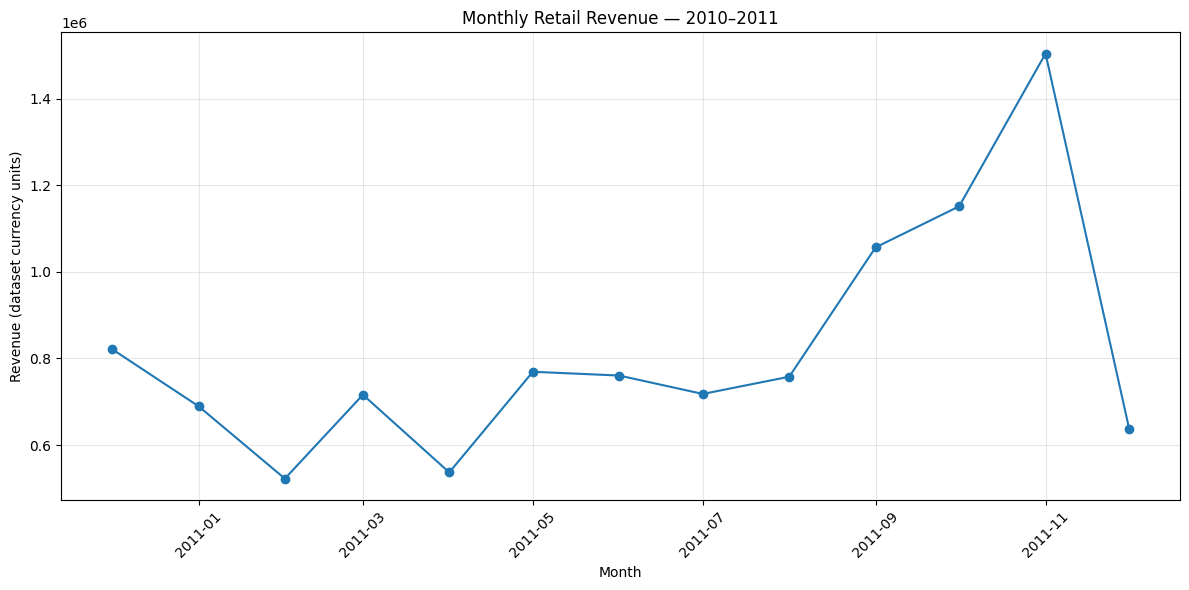

In [17]:
import matplotlib.pyplot as plt

monthly_sql["month"] = pd.to_datetime(monthly_sql["month"])

plt.figure(figsize=(12, 6))
plt.plot(
    monthly_sql["month"],
    monthly_sql["total_revenue"],
    marker="o"
)

plt.title("Monthly Retail Revenue — 2010–2011")
plt.xlabel("Month")
plt.ylabel("Revenue (dataset currency units)")
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()